In [1]:

import sys

print("¡Jupyter Notebook funciona correctamente!")
print("Versión de Python:", sys.version.split()[0])
print("Entorno de ejecución:", sys.executable)

¡Jupyter Notebook funciona correctamente!
Versión de Python: 3.12.10
Entorno de ejecución: c:\Users\PC\OneDrive\Escritorio\proyecto-git\MIA_Unidad_1_2\.venv\Scripts\python.exe


In [2]:

# Verificación de librerías del proyecto
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost as xgb

print("VERIFICACIÓN DE LIBRERÍAS")
print("-" * 40)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgb.__version__)

print("-" * 40)
print("Todas las librerías se importaron correctamente.")


VERIFICACIÓN DE LIBRERÍAS
----------------------------------------
NumPy: 2.5.4
Pandas: 3.1.1
Matplotlib: 3.11.2
Seaborn: 0.13.2
Scikit-learn: 1.9.1
XGBoost: 3.4.1
----------------------------------------
Todas las librerías se importaron correctamente.



# Métodos de Inteligencia Artificial
## Unidad 1 y Unidad 2

### 1. Introducción y análisis exploratorio de datos

El presente trabajo desarrolla un problema de clasificación binaria mediante algoritmos de aprendizaje automático supervisado.

Se utilizará un conjunto de datos de tumores mamarios para entrenar, evaluar y comparar diferentes modelos predictivos. La variable objetivo es Diagnosis, donde 0 representa un tumor benigno y 1 un tumor maligno.

El propósito es identificar el modelo con mejor capacidad de generalización y evaluar su desempeño mediante métricas apropiadas para clasificación binaria.

Profesor:   -Franco Mansilla Ibañez
Nombres:    -Néstor Pailamilla Molina
            -Sebastian Vargas Castillo

In [ ]:

# 1. cargo datos

import pandas as pd

# leo el csv
df = pd.read_csv("datos.csv")

# Veo sus dimensiones
print("Dimensiones del dataset:", df.shape)

# Nombres de las variables
print("\nVariables disponibles:")
print(df.columns.tolist())

# Visualización de las primeras 5 observaciones
display(df.head())


Dimensiones del dataset: (569, 11)

Variables disponibles:
['MeanRadius', 'MeanTexture', 'MeanPerimeter', 'MeanArea', 'MeanSmoothness', 'MeanCompactness', 'MeanConcavity', 'MeanConcavePoints', 'MeanSymmetry', 'MeanFractalDimension', 'Diagnosis']


,MeanRadius,MeanTexture,MeanPerimeter,MeanArea,MeanSmoothness,MeanCompactness,MeanConcavity,MeanConcavePoints,MeanSymmetry,MeanFractalDimension,Diagnosis
0,11.48,17.84,73.60,718.30,0.1096,0.0884,0.0754,0.0693,0.211,0.0567,0
1,14.09,17.18,58.10,591.10,0.1171,0.0635,0.0735,0.0284,0.178,0.0529,0
2,16.52,17.04,61.73,620.82,0.0912,0.0409,0.1499,0.0712,0.221,0.0542,0
3,15.14,21.38,90.91,459.59,0.0890,0.1193,0.0985,-0.0061,0.198,0.0587,0
4,13.20,23.94,76.36,754.18,0.0826,0.0063,0.0598,0.0863,0.144,0.0661,0



### 2. Análisis exploratorio de datos (EDA)

El análisis exploratorio permite comprender la estructura y calidad del conjunto de datos antes de aplicar algoritmos de Machine Learning.

Se analizarán los tipos de variables, valores faltantes, registros duplicados, distribución de diagnósticos y estadísticas descriptivas.

Estos resultados permitirán fundamentar las decisiones de preprocesamiento y entrenamiento.


In [4]:

# 2. ANÁLISIS EXPLORATORIO DE DATOS (EDA)

# 2.1 Tipos de variables
print("1. TIPOS DE VARIABLES")
display(df.dtypes.to_frame(name="Tipo de dato"))

# 2.2 Valores faltantes
print("\n2. VALORES FALTANTES")
display(df.isnull().sum().to_frame(name="Valores faltantes"))

# 2.3 Registros duplicados
print("\n3. REGISTROS DUPLICADOS")
print("Total de duplicados:", df.duplicated().sum())

# 2.4 Distribución de diagnósticos
print("\n4. DISTRIBUCIÓN DE DIAGNÓSTICOS")

conteo = df["Diagnosis"].value_counts().sort_index()
porcentaje = df["Diagnosis"].value_counts(
    normalize=True
).sort_index() * 100

distribucion = pd.DataFrame({
    "Cantidad": conteo,
    "Porcentaje (%)": porcentaje.round(2)
})

distribucion.index = ["Benigno (0)", "Maligno (1)"]
display(distribucion)

# 2.5 Estadísticas descriptivas
print("\n5. ESTADÍSTICAS DESCRIPTIVAS")

display(
    df.drop(columns="Diagnosis").describe().T.round(3)
)


1. TIPOS DE VARIABLES


,Tipo de dato
MeanRadius,float64
MeanTexture,float64
MeanPerimeter,float64
MeanArea,float64
MeanSmoothness,float64
MeanCompactness,float64
MeanConcavity,float64
MeanConcavePoints,float64
MeanSymmetry,float64
MeanFractalDimension,float64



2. VALORES FALTANTES


,Valores faltantes
MeanRadius,0
MeanTexture,0
MeanPerimeter,0
MeanArea,0
MeanSmoothness,0
MeanCompactness,0
MeanConcavity,0
MeanConcavePoints,0
MeanSymmetry,0
MeanFractalDimension,0



3. REGISTROS DUPLICADOS
Total de duplicados: 0

4. DISTRIBUCIÓN DE DIAGNÓSTICOS


,Cantidad,Porcentaje (%)
Benigno (0),357,62.74
Maligno (1),212,37.26



5. ESTADÍSTICAS DESCRIPTIVAS


,count,mean,std,min,25%,50%,75%,max
MeanRadius,569.0,14.240,2.912,5.940,12.350,14.240,16.180,22.610
MeanTexture,569.0,19.692,4.424,6.070,16.780,19.530,22.640,34.510
MeanPerimeter,569.0,97.406,16.951,45.100,86.570,97.700,109.100,145.010
MeanArea,569.0,729.323,191.242,205.300,589.000,733.720,852.360,1314.170
MeanSmoothness,569.0,0.099,0.014,0.058,0.090,0.099,0.108,0.146
MeanCompactness,569.0,0.107,0.052,-0.083,0.073,0.106,0.145,0.325
MeanConcavity,569.0,0.104,0.056,-0.044,0.066,0.104,0.140,0.267
MeanConcavePoints,569.0,0.058,0.032,-0.022,0.036,0.056,0.080,0.159
MeanSymmetry,569.0,0.186,0.032,0.093,0.163,0.187,0.207,0.283
MeanFractalDimension,569.0,0.064,0.007,0.043,0.059,0.064,0.068,0.084


In [ ]:

# 2.6 verifico valores

variables_revision = [
    "MeanCompactness",
    "MeanConcavity",
    "MeanConcavePoints"
]

# Identifico valores negativos
valores_negativos = df[variables_revision] < 0

print("VALORES NEGATIVOS POR VARIABLE")
print(valores_negativos.sum())

# Identifico filas afectadas
filas_negativas = valores_negativos.any(axis=1)

print("\nTotal de registros afectados:")
print(filas_negativas.sum())

print("\nDiagnósticos de los registros afectados:")
print(df.loc[filas_negativas, "Diagnosis"].value_counts())

# coloco una muestra
print("\nPrimeros 10 registros afectados:")
display(
    df.loc[
        filas_negativas,
        variables_revision + ["Diagnosis"]
    ].head(10)
)


VALORES NEGATIVOS POR VARIABLE
MeanCompactness      12
MeanConcavity        13
MeanConcavePoints    14
dtype: int64

Total de registros afectados:
38

Diagnósticos de los registros afectados:
Diagnosis
0    35
1     3
Name: count, dtype: int64

Primeros 10 registros afectados:


,MeanCompactness,MeanConcavity,MeanConcavePoints,Diagnosis
3,0.1193,0.0985,-0.0061,0
13,0.0550,-0.0173,0.0424,0
16,0.1257,0.0883,-0.0157,0
19,0.1055,0.0251,-0.0036,0
26,0.1737,-0.0339,0.0498,0
31,0.0138,-0.0053,0.0393,0
33,0.1757,0.2061,-0.0033,0
36,0.0746,-0.0033,0.0235,0
54,-0.0128,0.0080,0.0560,0
72,0.1083,-0.0120,0.1071,0



### 2.7 Interpretación de la calidad de datos

El conjunto de datos contiene 569 observaciones y 11 variables, de las cuales 10 son predictoras y una corresponde al diagnóstico.

No se identificaron valores faltantes ni registros duplicados. Sin embargo, se detectaron 38 observaciones (6,68 %) con valores negativos en las variables MeanCompactness, MeanConcavity y MeanConcavePoints.

Estos valores requieren revisión, debido a que las características geométricas representadas por estas variables son habitualmente no negativas.

De los 38 registros afectados, 35 corresponden a diagnósticos benignos y 3 a diagnósticos malignos.

Se conservarán temporalmente los registros originales durante el análisis exploratorio. Posteriormente se definirá y justificará una estrategia de preprocesamiento, evitando utilizar información de validación para ajustar las transformaciones.

La distribución de la variable objetivo presenta 62,74 % de casos benignos y 37,26 % de casos malignos. Por esta razón, la evaluación considerará métricas adicionales a Accuracy, especialmente Recall, F1-Score y AUC.


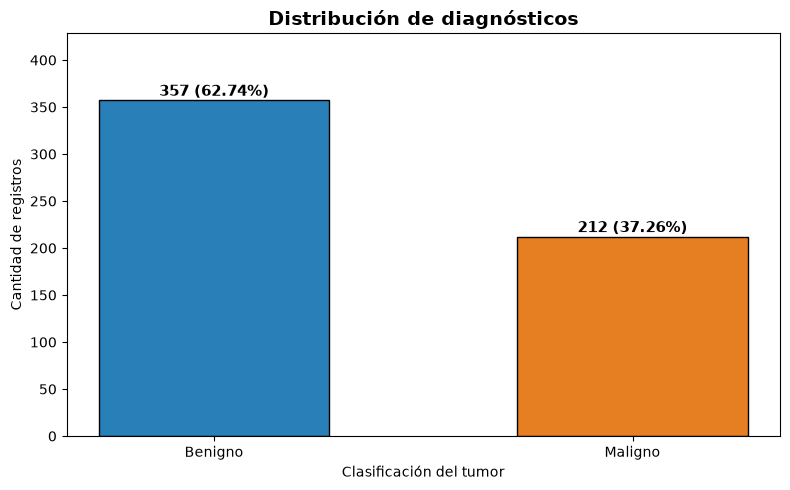

In [ ]:

# 2.8 distribución grafica de diagnosticos

import matplotlib.pyplot as plt

# Cuento diagnósticos
conteos = df["Diagnosis"].value_counts().sort_index()

clases = ["Benigno", "Maligno"]
colores = ["#2980B9", "#E67E22"]

# Creo gráfico
fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    clases,
    conteos.values,
    color=colores,
    edgecolor="black",
    width=0.55
)

# Agrego cantidades y porcentajes
for barra, cantidad in zip(barras, conteos.values):
    porcentaje = cantidad / len(df) * 100

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 5,
        f"{cantidad} ({porcentaje:.2f}%)",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Distribución de diagnósticos",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Clasificación del tumor")
ax.set_ylabel("Cantidad de registros")
ax.set_ylim(0, max(conteos.values) * 1.2)

plt.tight_layout()
plt.show()



### 2.9 Análisis de correlación entre variables

Se calculará la matriz de correlación de Pearson para identificar relaciones lineales entre las variables predictoras.

El análisis permitirá detectar posibles problemas de multicolinealidad, especialmente relevantes en modelos lineales regularizados.

Los valores de correlación varían entre -1 y 1. Los valores próximos a 1 indican una relación lineal positiva fuerte, mientras que los próximos a -1 indican una relación negativa fuerte.

Una correlación cercana a cero indica ausencia de una relación lineal fuerte, pero no necesariamente ausencia de otras relaciones.


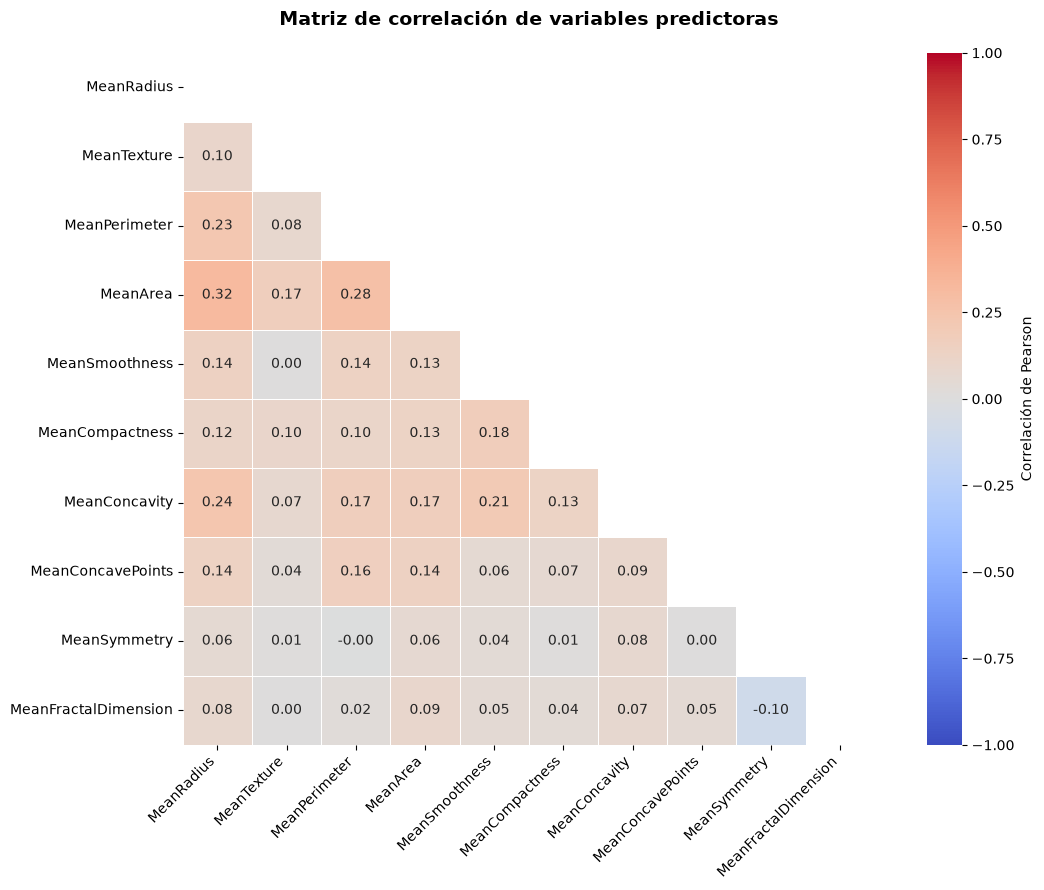

LAS 5 CORRELACIONES MÁS FUERTES:


Correlación
MeanArea      MeanRadius         0.319844
              MeanPerimeter      0.278104
MeanConcavity MeanRadius         0.236386
MeanPerimeter MeanRadius         0.234112
MeanConcavity MeanSmoothness     0.208779

In [ ]:

# 2.9 MATRIZ DE CORRELACIÓN

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Seleccionar las variables predictoras
X_eda = df.drop(columns=["Diagnosis"])

# Calcular correlaciones de Pearson
matriz_corr = X_eda.corr(method="pearson")

# Ocultar la mitad superior de la matriz
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))

# Creo gráfico
plt.figure(figsize=(12, 9))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlación de Pearson"}
)

plt.title(
    "Matriz de correlación de variables predictoras",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Identificar las correlaciones más fuertes
pares_corr = matriz_corr.where(
    np.tril(np.ones(matriz_corr.shape), k=-1).astype(bool)
).stack()

pares_corr = pares_corr.reindex(
    pares_corr.abs().sort_values(ascending=False).index
)

print("LAS 5 CORRELACIONES MÁS FUERTES:")
display(pares_corr.head(5).to_frame(name="Correlación"))



### 2.10 Interpretación de la matriz de correlación

El análisis de correlación de Pearson permitió evaluar las relaciones lineales entre las diez variables predictoras.

La correlación más elevada se presentó entre MeanArea y MeanRadius (r = 0,320), seguida de MeanArea y MeanPerimeter (r = 0,278).

En términos generales, las correlaciones obtenidas fueron bajas y no se identificaron relaciones lineales bivariadas superiores a 0,80 en valor absoluto.

Por lo tanto, no se considera necesario eliminar variables basándose exclusivamente en la correlación.

Se conservarán las diez variables predictoras para el entrenamiento inicial, permitiendo comparar el comportamiento de modelos regularizados, Random Forest, XGBoost y una red neuronal simple.



## 3. Preparación de los datos

### 3.1 División en entrenamiento y validación

Se realizará una división estratificada del conjunto de datos, destinando el 80 % de las observaciones al entrenamiento y el 20 % a la validación.

La estratificación permite mantener proporciones similares de diagnósticos benignos y malignos en ambos conjuntos.

Se utilizará una semilla aleatoria fija (random_state = 42) para garantizar la reproducibilidad.

El escalado y los demás tratamientos que requieran estimar parámetros se ajustarán únicamente con los datos de entrenamiento, evitando la fuga de información hacia el conjunto de validación.


In [8]:

# 3.1 DIVISIÓN DE DATOS

from sklearn.model_selection import train_test_split

# Variables predictoras
X = df.drop(columns=["Diagnosis"])

# Variable objetivo
y = df["Diagnosis"]

# División estratificada: 80% entrenamiento, 20% validación
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DIVISIÓN DEL CONJUNTO DE DATOS")
print("-" * 45)

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)

print("\nDISTRIBUCIÓN DE CLASES")

for nombre, etiquetas in [
    ("Entrenamiento", y_train),
    ("Validación", y_val)
]:
    print(f"\n{nombre}:")
    
    tabla = etiquetas.value_counts().sort_index()
    porcentajes = (
        etiquetas.value_counts(normalize=True)
        .sort_index() * 100
    )
    
    resumen = pd.DataFrame({
        "Cantidad": tabla,
        "Porcentaje (%)": porcentajes.round(2)
    })

    resumen.index = ["Benigno (0)", "Maligno (1)"]

    display(resumen)


DIVISIÓN DEL CONJUNTO DE DATOS
---------------------------------------------
Entrenamiento: (455, 10)
Validación: (114, 10)

DISTRIBUCIÓN DE CLASES

Entrenamiento:


,Cantidad,Porcentaje (%)
Benigno (0),285,62.64
Maligno (1),170,37.36



Validación:


,Cantidad,Porcentaje (%)
Benigno (0),72,63.16
Maligno (1),42,36.84



### 3.2 Interpretación de la división de datos

El conjunto de datos se dividió en 455 observaciones para entrenamiento (80 %) y 114 para validación (20 %).

En entrenamiento se obtuvieron 285 casos benignos (62,64 %) y 170 malignos (37,36 %).

En validación se obtuvieron 72 casos benignos (63,16 %) y 42 malignos (36,84 %).

La similitud entre ambas distribuciones confirma que la división estratificada preservó adecuadamente las proporciones de las clases.

El conjunto de validación permanecerá reservado para evaluar el desempeño de los modelos después de su entrenamiento y optimización mediante validación cruzada.



## 4. Entrenamiento de modelos supervisados

### 4.1 Regresión logística regularizada (Ridge / L2)

Se utilizará un modelo de regresión logística con penalización L2 para abordar el problema de clasificación binaria.

La penalización L2 reduce la magnitud de los coeficientes del modelo y contribuye a controlar su complejidad.

Se implementará un Pipeline de scikit-learn que incluye StandardScaler y LogisticRegression.

La estandarización se ajustará exclusivamente con los datos de entrenamiento para evitar la fuga de información hacia validación.

Inicialmente utilizaremos C = 1,0 como configuración de referencia. Posteriormente evaluaremos la optimización de hiperparámetros.


In [ ]:

# 4.1 MODELO REGULARIZADO: REGRESIÓN LOGÍSTICA L2

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Construcción del Pipeline
modelo_ridge = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=2000,
        random_state=42
    ))
])

# Entreno con la muestra de entrenamiento
modelo_ridge.fit(X_train, y_train)

# Predicciones sobre entrenamiento
y_pred_train = modelo_ridge.predict(X_train)

# Probabilidades de la clase maligna (1)
y_prob_train = modelo_ridge.predict_proba(X_train)[:, 1]

# Métricas preliminares
print("MODELO: REGRESIÓN LOGÍSTICA L2")
print("-" * 45)

print("Accuracy:",
      round(accuracy_score(y_train, y_pred_train), 4))

print("Precision:",
      round(precision_score(y_train, y_pred_train), 4))

print("Recall:",
      round(recall_score(y_train, y_pred_train), 4))

print("F1-Score:",
      round(f1_score(y_train, y_pred_train), 4))

print("AUC-ROC:",
      round(roc_auc_score(y_train, y_prob_train), 4))

print("-" * 45)
print("Entrenamiento completado correctamente.")


MODELO: REGRESIÓN LOGÍSTICA L2
---------------------------------------------
Accuracy: 0.9253
Precision: 0.9146
Recall: 0.8824
F1-Score: 0.8982
AUC-ROC: 0.9718
---------------------------------------------
Entrenamiento completado correctamente.



### 4.2 Interpretación del modelo de regresión logística L2

El modelo de regresión logística con penalización L2 obtuvo un Accuracy de 92,53 %, Precision de 91,46 %, Recall de 88,24 %, F1-Score de 89,82 % y AUC-ROC de 0,9718 en la muestra de entrenamiento.

El Recall obtenido indica que el modelo identificó correctamente 150 de los 170 casos malignos, generando 20 falsos negativos.

Desde la perspectiva del problema, los falsos negativos representan un error especialmente relevante, debido a que corresponden a tumores malignos clasificados como benignos.

El AUC-ROC de 0,9718 muestra una elevada capacidad de discriminación en la muestra de entrenamiento.

Sin embargo, estas métricas no permiten determinar todavía la capacidad de generalización. Para ello será necesario comparar el rendimiento mediante validación cruzada y evaluar posteriormente el conjunto de validación reservado.



### 4.3 Modelo Random Forest

Random Forest es un algoritmo supervisado de aprendizaje por ensamble que combina múltiples árboles de decisión.

Basados en construir árboles utilizando muestras aleatorias de los registros y subconjuntos de variables predictoras.

Para la clasificación binaria, el modelo combino las predicciones de los árboles para determinar la clase final.

Se entrenará inicialmente un modelo con 200 árboles y un mínimo de dos observaciones por hoja, utilizando únicamente el conjunto de entrenamiento.

Posteriormente se optimizarán sus hiperparámetros mediante validación cruzada.


In [ ]:

# 4.3 MODELO RANDOM FOREST

from sklearn.ensemble import RandomForestClassifier

# Creo el modelo
modelo_rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Entreno el modelo
modelo_rf.fit(X_train, y_train)

# Predecimos con el entrenamiento
y_pred_rf_train = modelo_rf.predict(X_train)

# Probabilidades de la clase maligna
y_prob_rf_train = modelo_rf.predict_proba(X_train)[:, 1]

# Evaluación del entrenamiento
print("MODELO: RANDOM FOREST")
print("-" * 45)

print("Accuracy:",
      round(accuracy_score(y_train, y_pred_rf_train), 4))

print("Precision:",
      round(precision_score(y_train, y_pred_rf_train), 4))

print("Recall:",
      round(recall_score(y_train, y_pred_rf_train), 4))

print("F1-Score:",
      round(f1_score(y_train, y_pred_rf_train), 4))

print("AUC-ROC:",
      round(roc_auc_score(y_train, y_prob_rf_train), 4))

print("-" * 45)
print("Random Forest entrenado correctamente.")


MODELO: RANDOM FOREST
---------------------------------------------
Accuracy: 0.9978
Precision: 1.0
Recall: 0.9941
F1-Score: 0.9971
AUC-ROC: 1.0
---------------------------------------------
Random Forest entrenado correctamente.



### 4.4 Interpretación del modelo Random Forest

El algoritmo Random Forest obtuvo los siguientes resultados sobre el conjunto de entrenamiento:

- Accuracy: 99,78 %
- Precision: 100 %
- Recall: 99,41 %
- F1-Score: 99,71 %
- AUC-ROC: 1,0000

El modelo clasificó correctamente 169 de los 170 casos malignos, generando un falso negativo.

En comparación con la regresión logística regularizada, Random Forest presentó un desempeño superior en todas las métricas evaluadas sobre entrenamiento.

Sin embargo, su rendimiento cercano al 100 % podría indicar sobreajuste. Esta posibilidad la comprobaremos mediante validación cruzada y evaluación con datos no utilizados durante el ajuste.


### 4.5 Modelo XGBoost

XGBoost (Extreme Gradient Boosting) es un algoritmo de aprendizaje supervisado basado en árboles de decisión y técnicas de boosting.

El modelo construyo árboles secuencialmente, buscando reducir los errores de predicción mediante la optimización de una función de pérdida.

Para este problema se utilizaremos XGBClassifier con el objetivo de clasificar binariamente y con una configuración inicial de hiperparámetros.

Se entrenará exclusivamente con el conjunto de entrenamiento y posteriormente se evaluará mediante validación cruzada.

La optimización de hiperparámetros se realizará en una etapa posterior, donde compararemos la consistencia entre los algoritmos.


In [ ]:

# 4.5 MODELO XGBOOST

from xgboost import XGBClassifier

# Crear modelo XGBoost
modelo_xgb = XGBClassifier(
    objective="binary:logistic",
    n_estimators=150,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Entrenaremos exclusivamente con los datos de entrenamiento
modelo_xgb.fit(X_train, y_train)

# Predicciones
y_pred_xgb_train = modelo_xgb.predict(X_train)

# Probabilidades de la clase maligna (1)
y_prob_xgb_train = modelo_xgb.predict_proba(X_train)[:, 1]

# Métricas de desempeño
print("MODELO: XGBOOST")
print("-" * 45)

print("Accuracy:",
      round(accuracy_score(y_train, y_pred_xgb_train), 4))

print("Precision:",
      round(precision_score(y_train, y_pred_xgb_train), 4))

print("Recall:",
      round(recall_score(y_train, y_pred_xgb_train), 4))

print("F1-Score:",
      round(f1_score(y_train, y_pred_xgb_train), 4))

print("AUC-ROC:",
      round(roc_auc_score(y_train, y_prob_xgb_train), 4))

print("-" * 45)
print("XGBoost entrenado correctamente.")


MODELO: XGBOOST
---------------------------------------------
Accuracy: 0.9824
Precision: 0.9821
Recall: 0.9706
F1-Score: 0.9763
AUC-ROC: 0.9979
---------------------------------------------
XGBoost entrenado correctamente.



### 4.6 Interpretación del modelo XGBoost

El algoritmo XGBoost obtuvo un Accuracy de 98,24 %, Precision de 98,21 %, Recall de 97,06 %, F1-Score de 97,63 % y AUC-ROC de 0,9979 en la muestra de entrenamiento.

El modelo identificó correctamente 165 de los 170 casos malignos, generando cinco falsos negativos y tres falsos positivos.

En comparación con la regresión logística L2, XGBoost obtuvo mejores resultados en todas las métricas evaluadas.

Random Forest presentó un desempeño superior al de XGBoost durante el entrenamiento. Sin embargo, esta diferencia no demuestra necesariamente una mejor capacidad de generalización.


### 4.7 Modelo de red neuronal simple 

al implementar la red neuronal artificial de tipo perceptrón multicapa (MLP), utilizamos MLPClassifier de scikit-learn.

Se utilizo la función de activación ReLU y el optimizador Adam.

Debido a que las redes neuronales son sensibles a las escalas de las variables, se implementamos un Pipeline con StandardScaler.

El modelo se entrenaro exclusivamente con la muestra de entrenamiento.


In [ ]:

# 4.7 MODELO DE RED NEURONAL SIMPLE

from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Creo red neuronal con una capa oculta
modelo_mlp = Pipeline([
    ("escalador", StandardScaler()),
    ("red_neuronal", MLPClassifier(
        hidden_layer_sizes=(16,),
        activation="relu",
        solver="adam",
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=2000,
        random_state=42
    ))
])

# Entreno con los datos de entrenamiento
modelo_mlp.fit(X_train, y_train)

# Predicciones de entrenamiento
y_pred_mlp_train = modelo_mlp.predict(X_train)

# Probabilidades de malignidad
y_prob_mlp_train = modelo_mlp.predict_proba(
    X_train
)[:, 1]

# Evaluación
print("MODELO: RED NEURONAL SIMPLE")
print("-" * 45)

print("Accuracy:",
      round(accuracy_score(y_train, y_pred_mlp_train), 4))

print("Precision:",
      round(precision_score(y_train, y_pred_mlp_train), 4))

print("Recall:",
      round(recall_score(y_train, y_pred_mlp_train), 4))

print("F1-Score:",
      round(f1_score(y_train, y_pred_mlp_train), 4))

print("AUC-ROC:",
      round(roc_auc_score(y_train, y_prob_mlp_train), 4))

print("-" * 45)
print("Red neuronal entrenada correctamente.")


MODELO: RED NEURONAL SIMPLE
---------------------------------------------
Accuracy: 0.9538
Precision: 0.9357
Recall: 0.9412
F1-Score: 0.9384
AUC-ROC: 0.9875
---------------------------------------------
Red neuronal entrenada correctamente.



### 4.8 Interpretación del modelo de red neuronal

La red neuronal simple obtuvo los siguientes resultados sobre el conjunto de entrenamiento:

- Accuracy: 95,38 %
- Precision: 93,57 %
- Recall: 94,12 %
- F1-Score: 93,84 %
- AUC-ROC: 0,9875

El modelo identificó correctamente 160 de los 170 casos malignos, generando 10 falsos negativos.

En comparación con la regresión logística L2, la red neuronal presentó un mejor desempeño en todas las métricas evaluadas.

No obstante, Random Forest y XGBoost obtuvieron resultados superiores durante el entrenamiento.

Estos resultados son preliminares. La selección del modelo final requerirá evaluar su capacidad de generalización mediante validación cruzada y comprobar posteriormente su desempeño sobre la muestra de validación reservada.

In [ ]:

# 5. EVALUACIÓN COMPARATIVA DE LOS MODELOS
# 5.1 Función general de métricas

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

# Reuno los cuatro modelos entrenados
modelos = {
    "Regresión logística L2": modelo_ridge,
    "Random Forest": modelo_rf,
    "XGBoost": modelo_xgb,
    "Red neuronal MLP": modelo_mlp
}

# Función de evaluación
def evaluar_modelo(nombre, modelo, X_datos, y_datos):

    # Predicción de clases
    y_pred = modelo.predict(X_datos)

    # Probabilidades de la clase maligna
    y_prob = modelo.predict_proba(X_datos)[:, 1]

    # Curva ROC para calcular KS
    fpr, tpr, umbrales = roc_curve(
        y_datos,
        y_prob
    )

    ks = max(tpr - fpr)

    # Resultados
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_datos, y_pred),
        "Precision": precision_score(
            y_datos, y_pred, zero_division=0
        ),
        "Recall": recall_score(y_datos, y_pred),
        "F1-Score": f1_score(y_datos, y_pred),
        "AUC-ROC": roc_auc_score(y_datos, y_prob),
        "KS": ks
    }


# Evaluo los cuatro modelos en entrenamiento
resultados = []

for nombre, modelo in modelos.items():

    metricas = evaluar_modelo(
        nombre,
        modelo,
        X_train,
        y_train
    )

    resultados.append(metricas)


# Crear tabla comparativa
tabla_entrenamiento = pd.DataFrame(resultados)

print("COMPARACIÓN GENERAL - ENTRENAMIENTO")
print("-" * 50)

display(
    tabla_entrenamiento.set_index("Modelo").round(4)
)


COMPARACIÓN GENERAL - ENTRENAMIENTO
--------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,KS
Modelo,,,,,,
Regresión logística L2,0.9253,0.9146,0.8824,0.8982,0.9718,0.8332
Random Forest,0.9978,1.0000,0.9941,0.9971,1.0000,1.0000
XGBoost,0.9824,0.9821,0.9706,0.9763,0.9979,0.9648
Red neuronal MLP,0.9538,0.9357,0.9412,0.9384,0.9875,0.9073



### 5.2 Análisis comparativo de los modelos

evaluamos cuatro algoritmos supervisados utilizando Accuracy, Precision, Recall, F1-Score, AUC-ROC y el estadístico Kolmogorov-Smirnov (KS).

Random Forest obtuvo el mayor desempeño en entrenamiento, alcanzando un Recall de 99,41 %, un F1-Score de 99,71 %, un AUC-ROC de 1,0000 y un KS de 1,0000.

XGBoost presentó resultados cercanos, con un Recall de 97,06 % y un AUC-ROC de 0,9979.

La red neuronal simple obtuvo mejores resultados que la regresión logística regularizada en todas las métricas.

Desde la perspectiva del problema, el Recall resulta especialmente relevante porque nos permite cuantificar la proporción de casos malignos correctamente identificados.

Sin embargo, el desempeño casi perfecto de Random Forest en entrenamiento requiere comprobar su capacidad de generalización.

Por lo tanto, se aplicará optimización de hiperparámetros mediante validación cruzada estratificada, utilizando exclusivamente los datos de entrenamiento.



## 6. Optimización de hiperparámetros

### 6.1 Método GridSearchCV

Se utilizamos GridSearchCV con validación cruzada estratificada de cinco particiones.

Este procedimiento nos permite evaluar diferentes configuraciones de hiperparámetros y seleccionar aquellas que presentan mejor desempeño promedio en validación cruzada.
El criterio de optimización será F1-Score, considerando adicionalmente Recall y AUC-ROC.
La búsqueda se realizará sobre el conjunto de entrenamiento.

### 6.2 Optimización de regresión logística L2
Se optimizo el parámetro C, que controla la intensidad de regularización.
Valores pequeños de C representan una regularización más fuerte, mientras que valores elevados corresponden a una regularización más débil.

In [ ]:

# 6.2 OPTIMIZACIÓN DE REGRESIÓN LOGÍSTICA L2

from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold
)

# Validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Valores del hiperparámetro a evaluar
parametros_ridge = {
    "clasificador__C": [0.01, 0.1, 1, 10, 100]
}

# Configuro búsqueda
busqueda_ridge = GridSearchCV(
    estimator=modelo_ridge,
    param_grid=parametros_ridge,
    scoring={
        "f1": "f1",
        "recall": "recall",
        "auc": "roc_auc"
    },
    refit="f1",
    cv=cv,
    n_jobs=1,
    return_train_score=True
)

# Ejecuto búsqueda con los datos de entrenamiento
busqueda_ridge.fit(X_train, y_train)

# Guardo el mejor modelo
modelo_ridge_optimizado = busqueda_ridge.best_estimator_

print("OPTIMIZACIÓN DE REGRESIÓN LOGÍSTICA L2")
print("-" * 50)

print("Mejor parámetro:")
print(busqueda_ridge.best_params_)

print("\nMejor F1-Score promedio:")
print(round(busqueda_ridge.best_score_, 4))

# Muestro resultados de todas las configuraciones
resultados_ridge = pd.DataFrame(
    busqueda_ridge.cv_results_
)

columnas = [
    "param_clasificador__C",
    "mean_test_f1",
    "mean_test_recall",
    "mean_test_auc",
    "std_test_f1"
]

print("\nRESULTADOS DE VALIDACIÓN CRUZADA")

display(
    resultados_ridge[columnas]
    .sort_values("mean_test_f1", ascending=False)
    .round(4)
)


OPTIMIZACIÓN DE REGRESIÓN LOGÍSTICA L2
--------------------------------------------------
Mejor parámetro:
{'clasificador__C': 10}

Mejor F1-Score promedio:
0.8819

RESULTADOS DE VALIDACIÓN CRUZADA


,param_clasificador__C,mean_test_f1,mean_test_recall,mean_test_auc,std_test_f1
4,100.00,0.8819,0.8588,0.9655,0.0269
3,10.00,0.8819,0.8588,0.9655,0.0269
1,0.10,0.8815,0.8588,0.9667,0.0271
2,1.00,0.8792,0.8588,0.9654,0.0227
0,0.01,0.8484,0.7824,0.9679,0.0470



### 6.3 Resultados de optimización de regresión logística L2

La optimización mediante GridSearchCV evaluó cinco valores del hiperparámetro C utilizando validación cruzada estratificada de cinco particiones.

El procedimiento seleccionó C = 10, obteniendo un F1-Score promedio de 0,8819, Recall de 0,8588 y AUC-ROC de 0,9655.
Los valores C = 10 y C = 100 presentaron resultados prácticamente equivalentes en las métricas reportadas.
Por otra parte, C = 0,01 obtuvo el menor F1-Score (0,8484), lo que sugiere que una regularización más intensa perjudica el equilibrio entre Precision y Recall para este conjunto de datos.
Se conservará el modelo optimizado para su posterior evaluación y comparación con los demás algoritmos.


### 6.4 Optimización de Random Forest

Se aplicará GridSearchCV para optimizar los hiperparámetros de Random Forest.

Se evaluarán diferentes cantidades de árboles, profundidades máximas y tamaños mínimos de hojas.

El objetivo será identificar una configuración que presente un adecuado equilibrio entre capacidad predictiva y generalización.

Se utilizará validación cruzada estratificada de cinco particiones y F1-Score como criterio principal de selección.

Adicionalmente, se calcularán Recall y AUC-ROC para evaluar la capacidad de detección y discriminación de casos malignos.


In [ ]:

# 6.4 OPTIMIZACIÓN DE RANDOM FOREST

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Modelo base para la búsqueda
rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

# Hiperparámetros a evaluar
parametros_rf = {
    "n_estimators": [100, 150],
    "max_depth": [5, None],
    "min_samples_leaf": [1, 3]
}

# Configuro GridSearchCV
busqueda_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=parametros_rf,
    scoring={
        "f1": "f1",
        "recall": "recall",
        "auc": "roc_auc"
    },
    refit="f1",
    cv=cv,
    n_jobs=1,
    return_train_score=True
)

# Optimizo utilizando solo entrenamiento
busqueda_rf.fit(X_train, y_train)

# Guardo el modelo optimizado
modelo_rf_optimizado = busqueda_rf.best_estimator_

print("OPTIMIZACIÓN DE RANDOM FOREST")
print("-" * 50)

print("Mejores hiperparámetros:")
print(busqueda_rf.best_params_)

print("\nMejor F1-Score promedio:")
print(round(busqueda_rf.best_score_, 4))

# Tabla de resultados
resultados_rf = pd.DataFrame(
    busqueda_rf.cv_results_
)

columnas_rf = [
    "param_n_estimators",
    "param_max_depth",
    "param_min_samples_leaf",
    "mean_test_f1",
    "mean_test_recall",
    "mean_test_auc",
    "std_test_f1"
]

print("\nRESULTADOS DE VALIDACIÓN CRUZADA")

display(
    resultados_rf[columnas_rf]
    .sort_values("mean_test_f1", ascending=False)
    .round(4)
)


OPTIMIZACIÓN DE RANDOM FOREST
--------------------------------------------------
Mejores hiperparámetros:
{'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 100}

Mejor F1-Score promedio:
0.8369

RESULTADOS DE VALIDACIÓN CRUZADA


,param_n_estimators,param_max_depth,param_min_samples_leaf,mean_test_f1,mean_test_recall,mean_test_auc,std_test_f1
0,100,5,1,0.8369,0.8118,0.9543,0.0570
4,100,None,1,0.8366,0.8059,0.9545,0.0458
5,150,None,1,0.8338,0.8059,0.9555,0.0441
1,150,5,1,0.8289,0.7941,0.9573,0.0473
6,100,None,3,0.8258,0.8059,0.9533,0.0439
7,150,None,3,0.8180,0.7882,0.9550,0.0432
2,100,5,3,0.8176,0.8000,0.9522,0.0475
3,150,5,3,0.8166,0.7882,0.9543,0.0295



### 6.5 Resultados de optimización de Random Forest

La optimización de Random Forest se realizó mediante GridSearchCV, utilizando validación cruzada estratificada de cinco particiones.

Evaluamos ocho combinaciones de hiperparámetros, considerando el número de árboles, la profundidad máxima y la cantidad mínima de observaciones por hoja.

La mejor configuración encontrada fue:

- n_estimators = 100
- max_depth = 5
- min_samples_leaf = 1

Esta configuración obtuvo un F1-Score promedio de 0,8369, Recall de 0,8118 y AUC-ROC de 0,9543.
Estos resultados son inferiores a los de la regresión logística L2 optimizada, que alcanzó un F1-Score promedio de 0,8819.
La diferencia entre el rendimiento casi perfecto de Random Forest en entrenamiento y sus resultados de validación cruzada sugiere posibles dificultades de generalización.


### 6.6 Optimización de XGBoost

Se aplicaremos GridSearchCV al algoritmo XGBoost, utilizando validación cruzada estratificada de cinco particiones.

Se optimizaron tres hiperparámetros:

- n_estimators: número de árboles.
- max_depth: profundidad máxima de los árboles.
- learning_rate: tasa de aprendizaje.

La búsqueda utilizará F1-Score como criterio principal de selección y calculará adicionalmente Recall y AUC-ROC.

El objetivo será encontrar una configuración con buen desempeño predictivo y capacidad de generalización, evitando seleccionar un modelo únicamente por sus resultados de entrenamiento.


In [16]:

# 6.6 OPTIMIZACIÓN DE XGBOOST

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

# Modelo base
xgb_base = XGBClassifier(
    objective="binary:logistic",
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

# Hiperparámetros a optimizar
parametros_xgb = {
    "n_estimators": [100, 200],
    "max_depth": [2, 3],
    "learning_rate": [0.05, 0.1]
}

# Configuración de GridSearchCV
busqueda_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=parametros_xgb,
    scoring={
        "f1": "f1",
        "recall": "recall",
        "auc": "roc_auc"
    },
    refit="f1",
    cv=cv,
    n_jobs=1,
    return_train_score=True
)

# Entrenamiento y optimización
busqueda_xgb.fit(X_train, y_train)

# Guardar mejor modelo
modelo_xgb_optimizado = busqueda_xgb.best_estimator_

print("OPTIMIZACIÓN DE XGBOOST")
print("-" * 50)

print("Mejores hiperparámetros:")
print(busqueda_xgb.best_params_)

print("\nMejor F1-Score promedio:")
print(round(busqueda_xgb.best_score_, 4))

# Resultados de validación cruzada
resultados_xgb = pd.DataFrame(
    busqueda_xgb.cv_results_
)

columnas_xgb = [
    "param_n_estimators",
    "param_max_depth",
    "param_learning_rate",
    "mean_test_f1",
    "mean_test_recall",
    "mean_test_auc",
    "std_test_f1"
]

print("\nRESULTADOS DE VALIDACIÓN CRUZADA")

display(
    resultados_xgb[columnas_xgb]
    .sort_values(
        "mean_test_f1",
        ascending=False
    )
    .round(4)
)


OPTIMIZACIÓN DE XGBOOST
--------------------------------------------------
Mejores hiperparámetros:
{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}

Mejor F1-Score promedio:
0.8417

RESULTADOS DE VALIDACIÓN CRUZADA


,param_n_estimators,param_max_depth,param_learning_rate,mean_test_f1,mean_test_recall,mean_test_auc,std_test_f1
5,200,2,0.10,0.8417,0.8353,0.9559,0.0377
4,100,2,0.10,0.8307,0.8118,0.9560,0.0300
1,200,2,0.05,0.8252,0.7941,0.9543,0.0627
2,100,3,0.05,0.8214,0.8000,0.9512,0.0498
3,200,3,0.05,0.8203,0.7941,0.9527,0.0346
6,100,3,0.10,0.8198,0.8059,0.9526,0.0344
7,200,3,0.10,0.8139,0.8000,0.9508,0.0574
0,100,2,0.05,0.8122,0.7824,0.9504,0.0516



### 6.7 Resultados de optimización de XGBoost

La optimización de XGBoost se desarrolló mediante GridSearchCV, utilizando validación cruzada estratificada de cinco particiones.

Se evaluaron ocho combinaciones de hiperparámetros, considerando la tasa de aprendizaje, profundidad máxima y número de árboles.

La mejor configuración encontrada fue:

- learning_rate = 0.1
- max_depth = 2
- n_estimators = 200

El modelo obtuvo un F1-Score promedio de 0,8417, Recall de 0,8353 y AUC-ROC de 0,9559.

En comparación con Random Forest optimizado (F1 = 0,8369), XGBoost presentó un desempeño ligeramente superior.

Sin embargo, la regresión logística L2 continúa mostrando el mayor F1-Score promedio (0,8819) entre los tres algoritmos optimizados.

Los resultados corresponden a validación cruzada interna, por lo que todavía no representan la evaluación final sobre el conjunto de validación reservado.


### 6.8 Optimización de la red neuronal simple

Se aplicará GridSearchCV para optimizar los hiperparámetros de la red neuronal MLPClassifier.

Se evaluo la cantidad de neuronas de la capa oculta y la intensidad de regularización L2.

El propósito será identificar una arquitectura que permita obtener un adecuado equilibrio entre Precision y Recall, evitando una complejidad innecesaria.

Se utilizará validación cruzada estratificada de cinco particiones y F1-Score como criterio principal.

La red neuronal incorporará StandardScaler dentro del Pipeline, garantizando que la estandarización se ajuste únicamente con los datos correspondientes a cada partición de entrenamiento.


In [ ]:

# 6.8 OPTIMIZACIÓN DE RED NEURONAL SIMPLE

from sklearn.model_selection import GridSearchCV

# Hiperparámetros a evaluar
parametros_mlp = {
    "red_neuronal__hidden_layer_sizes": [(8,), (16,)],
    "red_neuronal__alpha": [0.001, 0.01]
}

# Configuro búsqueda
busqueda_mlp = GridSearchCV(
    estimator=modelo_mlp,
    param_grid=parametros_mlp,
    scoring={
        "f1": "f1",
        "recall": "recall",
        "auc": "roc_auc"
    },
    refit="f1",
    cv=cv,
    n_jobs=1,
    return_train_score=True
)

# Optimizo con datos de entrenamiento
busqueda_mlp.fit(X_train, y_train)

# Guardo mejor modelo
modelo_mlp_optimizado = busqueda_mlp.best_estimator_

print("OPTIMIZACIÓN DE RED NEURONAL SIMPLE")
print("-" * 50)

print("Mejores hiperparámetros:")
print(busqueda_mlp.best_params_)

print("\nMejor F1-Score promedio:")
print(round(busqueda_mlp.best_score_, 4))

# Resultados de validación cruzada
resultados_mlp = pd.DataFrame(
    busqueda_mlp.cv_results_
)

columnas_mlp = [
    "param_red_neuronal__hidden_layer_sizes",
    "param_red_neuronal__alpha",
    "mean_test_f1",
    "mean_test_recall",
    "mean_test_auc",
    "std_test_f1",
    "mean_train_f1"
]

print("\nRESULTADOS DE VALIDACIÓN CRUZADA")

display(
    resultados_mlp[columnas_mlp]
    .sort_values(
        "mean_test_f1",
        ascending=False
    )
    .round(4)
)


OPTIMIZACIÓN DE RED NEURONAL SIMPLE
--------------------------------------------------
Mejores hiperparámetros:
{'red_neuronal__alpha': 0.001, 'red_neuronal__hidden_layer_sizes': (8,)}

Mejor F1-Score promedio:
0.87

RESULTADOS DE VALIDACIÓN CRUZADA


,param_red_neuronal__hidden_layer_sizes,param_red_neuronal__alpha,mean_test_f1,mean_test_recall,mean_test_auc,std_test_f1,mean_train_f1
0,"(8,)",0.001,0.8700,0.8647,0.9649,0.0272,0.9025
2,"(8,)",0.010,0.8700,0.8647,0.9645,0.0272,0.9025
1,"(16,)",0.001,0.8657,0.8353,0.9599,0.0189,0.9415
3,"(16,)",0.010,0.8657,0.8353,0.9602,0.0189,0.9422



### 6.9 Resultados de optimización de la red neuronal
La optimización de la red neuronal MLP se realizó mediante GridSearchCV y validación cruzada estratificada de cinco particiones.
La mejor configuración seleccionada fue una capa oculta de ocho neuronas y un parámetro de regularización alpha = 0,001.
El modelo obtuvo un F1-Score promedio de 0,8700, Recall de 0,8647 y AUC-ROC de 0,9649.
El F1-Score promedio de entrenamiento fue 0,9025, mientras que en validación cruzada fue 0,8700.
La arquitectura de ocho neuronas mostró una menor diferencia entre entrenamiento y validación cruzada que la arquitectura de 16 neuronas.
Al comparar los cuatro algoritmos optimizados, la regresión logística L2 alcanzó el mayor F1-Score promedio (0,8819), seguida de la red neuronal (0,8700), XGBoost (0,8417) y Random Forest (0,8369).
La red neuronal obtuvo el Recall promedio más elevado (0,8647).
Estos resultados permiten identificar modelos candidatos, pero todavía es necesario evaluar su comportamiento en el conjunto de validación reservado.


## 7. Evaluación de los modelos optimizados

### 7.1 Comparación de entrenamiento y validación

Se evaluarán los cuatro modelos optimizados utilizando las muestras de entrenamiento y validación.

Se calcularán Accuracy, Precision, Recall, F1-Score, AUC-ROC y KS.

El propósito será comprobar la capacidad de generalización, identificar posibles diferencias de rendimiento y fundamentar la selección del modelo final.

La muestra de validación contiene 114 registros que no participaron en el entrenamiento ni en la optimización de hiperparámetros.

No se realizarán nuevos ajustes basados en sus resultados.


In [18]:

# 7.1 EVALUACIÓN FINAL DE LOS MODELOS OPTIMIZADOS

# Modelos seleccionados por GridSearchCV
modelos_optimizados = {
    "Regresión logística L2": modelo_ridge_optimizado,
    "Random Forest": modelo_rf_optimizado,
    "XGBoost": modelo_xgb_optimizado,
    "Red neuronal MLP": modelo_mlp_optimizado
}

# Lista para almacenar resultados
resultados_finales = []

# Evaluar entrenamiento y validación
for nombre, modelo in modelos_optimizados.items():

    # Métricas de entrenamiento
    metricas_train = evaluar_modelo(
        nombre, modelo, X_train, y_train
    )

    metricas_train["Muestra"] = "Entrenamiento"

    # Métricas de validación
    metricas_val = evaluar_modelo(
        nombre, modelo, X_val, y_val
    )

    metricas_val["Muestra"] = "Validación"

    resultados_finales.extend([
        metricas_train,
        metricas_val
    ])

# Crear tabla comparativa
tabla_final = pd.DataFrame(resultados_finales)

columnas = [
    "Modelo",
    "Muestra",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "AUC-ROC",
    "KS"
]

tabla_final = tabla_final[columnas]

print("COMPARACIÓN DE MODELOS OPTIMIZADOS")
print("-" * 55)

display(
    tabla_final.set_index(
        ["Modelo", "Muestra"]
    ).round(4)
)


COMPARACIÓN DE MODELOS OPTIMIZADOS
-------------------------------------------------------


Accuracy  Precision  Recall  F1-Score  \
Modelo                 Muestra                                                
Regresión logística L2 Entrenamiento    0.9231     0.9141  0.8765    0.8949   
                       Validación       0.9123     0.9211  0.8333    0.8750   
Random Forest          Entrenamiento    0.9692     0.9875  0.9294    0.9576   
                       Validación       0.9123     0.9444  0.8095    0.8718   
XGBoost                Entrenamiento    0.9890     0.9882  0.9824    0.9853   
                       Validación       0.9035     0.9429  0.7857    0.8571   
Red neuronal MLP       Entrenamiento    0.9253     0.9096  0.8882    0.8988   
                       Validación       0.9035     0.8780  0.8571    0.8675   

                                      AUC-ROC      KS  
Modelo                 Muestra                         
Regresión logística L2 Entrenamiento   0.9718  0.8333  
                       Validación      0.9712  0.8313  
Random Forest          Entrenamiento   0.9963  0.9519  
                       Validación      0.9567  0.8016  
XGBoost                Entrenamiento   0.9984  0.9753  
                       Validación      0.9683  0.8016  
Red neuronal MLP       Entrenamiento   0.9772  0.8628  
                       Validación      0.9669  0.8115


### 7.2 Matrices de confusión

Se construirán matrices de confusión para los cuatro modelos optimizados, utilizando exclusivamente el conjunto de validación.

Cada matriz permitirá identificar:

- Verdaderos negativos (VN): tumores benignos correctamente clasificados.
- Falsos positivos (FP): tumores benignos clasificados como malignos.
- Falsos negativos (FN): tumores malignos clasificados como benignos.
- Verdaderos positivos (VP): tumores malignos correctamente identificados.

En este problema, los falsos negativos tienen especial importancia porque representan casos malignos que el modelo no detecta.

Las matrices permitirán complementar la interpretación de Accuracy, Precision, Recall y F1-Score.


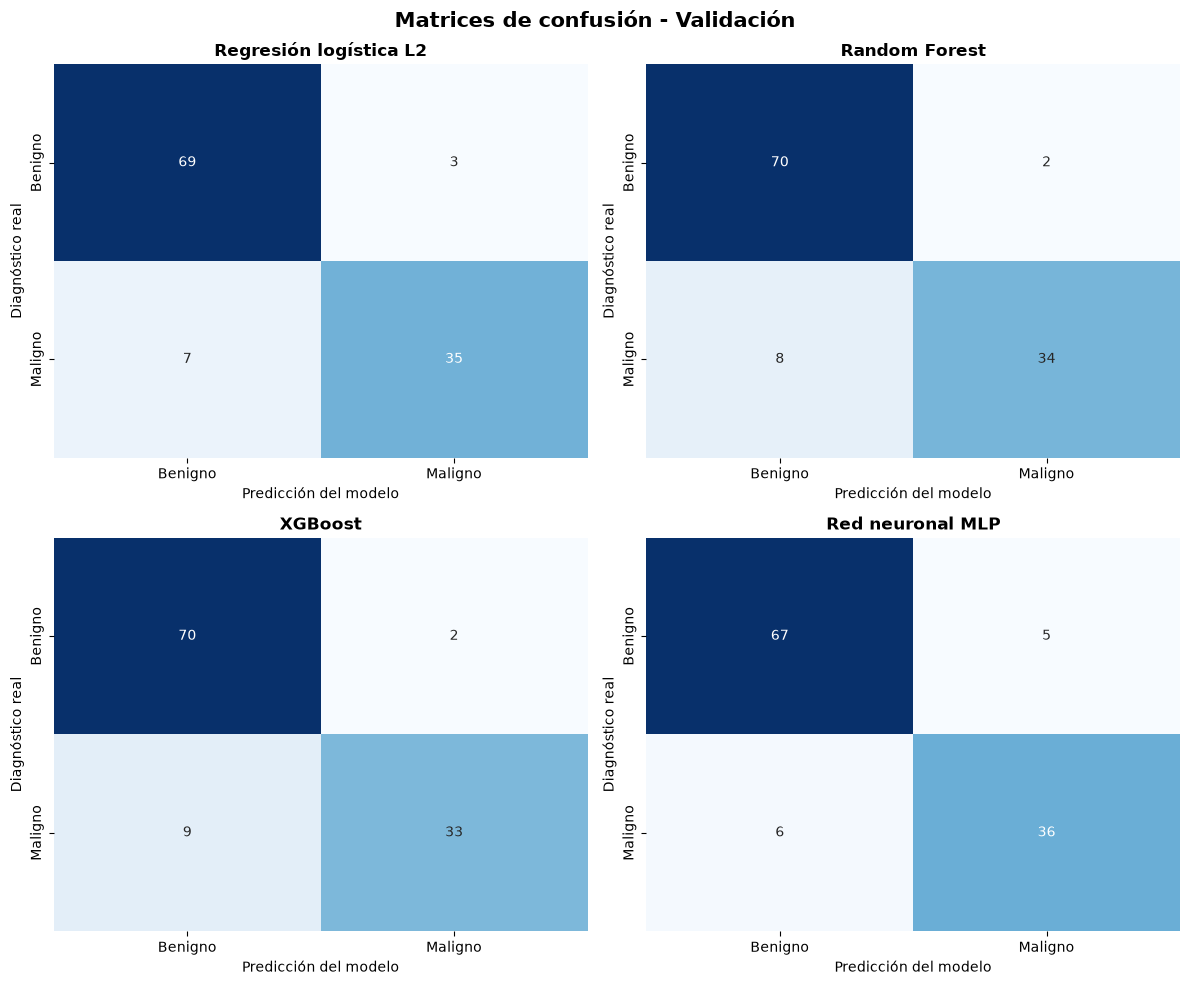

RESUMEN DE MATRICES DE CONFUSIÓN
--------------------------------------------------


,VN,FP,FN,VP
Modelo,,,,
Regresión logística L2,69,3,7,35
Random Forest,70,2,8,34
XGBoost,70,2,9,33
Red neuronal MLP,67,5,6,36


In [19]:

# 7.2 MATRICES DE CONFUSIÓN DE LOS MODELOS OPTIMIZADOS

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import confusion_matrix

# Crear figura con cuatro gráficos
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

resultados_confusion = []

# Recorrer los modelos optimizados
for ax, (nombre, modelo) in zip(
    axes.flatten(),
    modelos_optimizados.items()
):

    # Predicciones sobre validación
    y_pred = modelo.predict(X_val)

    # Matriz de confusión
    matriz = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    )

    # Extraer valores
    vn, fp, fn, vp = matriz.ravel()

    # Guardar resultados
    resultados_confusion.append({
        "Modelo": nombre,
        "VN": vn,
        "FP": fp,
        "FN": fn,
        "VP": vp
    })

    # Visualizar matriz
    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Benigno", "Maligno"],
        yticklabels=["Benigno", "Maligno"],
        ax=ax
    )

    ax.set_title(nombre, fontweight="bold")
    ax.set_xlabel("Predicción del modelo")
    ax.set_ylabel("Diagnóstico real")

plt.suptitle(
    "Matrices de confusión - Validación",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Tabla de errores y aciertos
tabla_confusion = pd.DataFrame(
    resultados_confusion
).set_index("Modelo")

print("RESUMEN DE MATRICES DE CONFUSIÓN")
print("-" * 50)

display(tabla_confusion)



### 7.3 Interpretación de las matrices de confusión

Las matrices de confusión permitieron analizar los errores de clasificación de los cuatro modelos optimizados sobre las 114 observaciones de validación.

La regresión logística L2 clasificó correctamente 104 observaciones, generando tres falsos positivos y siete falsos negativos.

Random Forest también obtuvo 104 clasificaciones correctas, con dos falsos positivos y ocho falsos negativos.

XGBoost clasificó correctamente 103 observaciones, generando dos falsos positivos y nueve falsos negativos.

La red neuronal MLP obtuvo 103 clasificaciones correctas, con cinco falsos positivos y seis falsos negativos.

La red neuronal presentó la menor cantidad de falsos negativos, lo que explica su mayor Recall.

Sin embargo, la regresión logística L2 obtuvo un mejor equilibrio entre Precision y Recall, reflejado en su F1-Score de 0,8750.

Los resultados evidencian que diferentes métricas pueden favorecer modelos distintos. Por ello, la selección final debe considerar tanto el desempeño estadístico como las consecuencias de los errores de clasificación.

El análisis corresponde a un ejercicio académico y no constituye una validación para uso diagnóstico clínico.



### 7.4 Análisis de curvas ROC

Se construirán las curvas ROC de los cuatro modelos optimizados utilizando las probabilidades estimadas sobre el conjunto de validación.

La curva ROC representa la relación entre la sensibilidad (TPR) y la tasa de falsos positivos (FPR) para diferentes umbrales de clasificación.

El área bajo la curva (AUC-ROC) permite evaluar la capacidad discriminativa de cada algoritmo sin depender de un único umbral.

Un AUC cercano a 1 indica una mayor capacidad para distinguir entre tumores benignos y malignos.

El análisis complementará las métricas de clasificación y las matrices de confusión, contribuyendo a la justificación del modelo final.


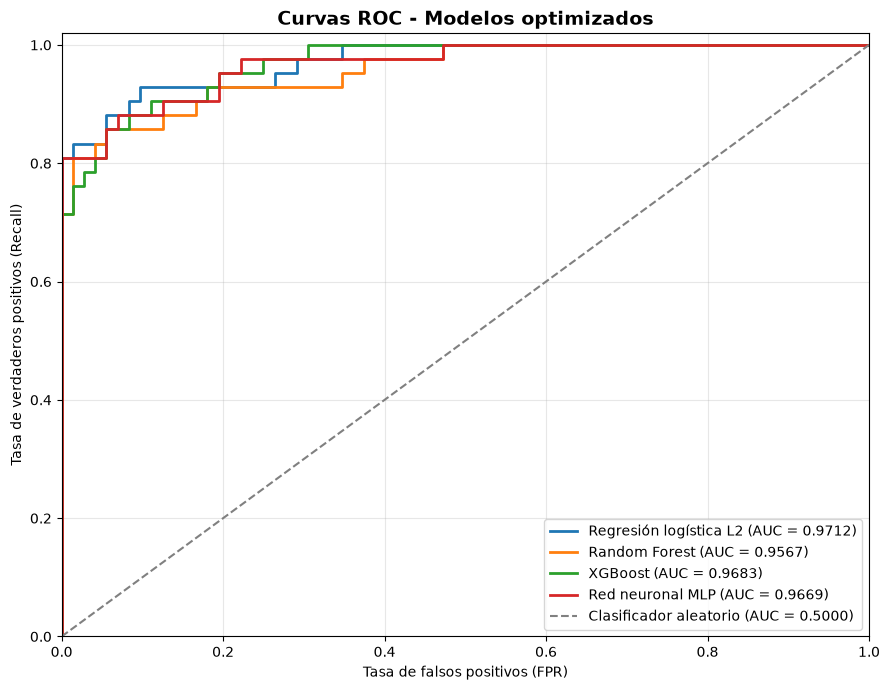

In [20]:

# 7.4 CURVAS ROC DE LOS CUATRO MODELOS

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# Crear figura
fig, ax = plt.subplots(figsize=(9, 7))

# Evaluar cada modelo optimizado
for nombre, modelo in modelos_optimizados.items():

    # Probabilidad de diagnóstico maligno
    y_prob = modelo.predict_proba(X_val)[:, 1]

    # Calcular curva ROC
    fpr, tpr, umbrales = roc_curve(
        y_val,
        y_prob,
        pos_label=1
    )

    # Calcular AUC
    auc = roc_auc_score(y_val, y_prob)

    # Graficar curva
    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{nombre} (AUC = {auc:.4f})"
    )

# Línea de referencia: clasificador aleatorio
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificador aleatorio (AUC = 0.5000)"
)

# Configuración del gráfico
ax.set_title(
    "Curvas ROC - Modelos optimizados",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



## 8. Interpretación de resultados y selección del modelo final

### 8.1 Interpretación de las curvas ROC

Las curvas ROC nos permitio comparar la capacidad discriminativa de los cuatro modelos optimizados sobre el conjunto de validación.

Los resultados de AUC-ROC fueron:

- Regresión logística L2: 0,9712.
- XGBoost: 0,9683.
- Red neuronal MLP: 0,9669.
- Random Forest: 0,9567.

Los cuatro modelos presentaron valores elevados de AUC-ROC, indicando una buena capacidad discriminativa en los datos evaluados.

La regresión logística L2 obtuvo el mayor AUC-ROC, aunque las diferencias observadas no permiten establecer superioridad estadística sin análisis adicionales.

### 8.2 Selección del modelo final

Se selecciona la regresión logística con penalización L2 como modelo final.

La decisión se fundamenta principalmente en los siguientes resultados:

1. Obtuvo el mayor F1-Score promedio en validación cruzada (0,8819).
2. Alcanzó el mayor F1-Score en la muestra de validación reservada (0,8750).
3. Presentó el AUC-ROC más elevado en validación (0,9712).
4. Registró una diferencia relativamente pequeña entre el F1-Score de entrenamiento (0,8949) y validación (0,8750).
5. Su estructura regularizada permite una interpretación más directa de los coeficientes que los modelos basados en ensambles y redes neuronales.

La configuración seleccionada mediante GridSearchCV corresponde a C = 10.

### 8.3 Consideraciones sobre los errores de clasificación

La matriz de confusión del modelo seleccionado presentó:

- 69 verdaderos negativos.
- 3 falsos positivos.
- 7 falsos negativos.
- 35 verdaderos positivos.

El Recall de 0,8333 indica que el modelo identificó correctamente el 83,33 % de los casos malignos de validación.

La red neuronal MLP presentó un Recall superior (0,8571), identificando un caso maligno adicional, aunque también generó más falsos positivos.

Por tanto, la selección depende del criterio de desempeño y del costo asociado a los distintos errores.

### 8.4 Limitaciones del análisis

Los resultados corresponden a un conjunto de datos de 569 observaciones, por lo que las estimaciones pueden presentar variabilidad muestral.

Se identificaron 38 registros con valores negativos en variables geométricas. Estos registros se conservaron sin modificaciones al no disponer de evidencia suficiente sobre su origen.

La muestra reservada se utilizó para comparar los modelos, por lo que sería necesaria una prueba externa independiente para obtener una estimación adicional de desempeño después de la selección.

### 8.5 Conclusión de la comparación

Los resultados muestran que una mayor complejidad algorítmica no garantiza un mejor desempeño sobre datos no utilizados durante el entrenamiento.

Aunque Random Forest y XGBoost obtuvieron métricas cercanas a la perfección durante el entrenamiento, sus resultados disminuyeron en validación.

La regresión logística regularizada presentó el mejor equilibrio general según el criterio F1-Score utilizado durante la optimización.

Esto demuestra la importancia de utilizar validación cruzada, métricas adecuadas y procedimientos reproducibles para fundamentar la selección de modelos de Machine Learning.



## 9. Conclusión general

El presente trabajo permitió aplicar y comparar cuatro algoritmos de aprendizaje automático supervisado para resolver un problema de clasificación binaria de tumores mamarios: regresión logística regularizada L2, Random Forest, XGBoost y una red neuronal simple.

Se analizaron 569 observaciones, distribuidas en 455 registros de entrenamiento y 114 de validación. Durante el análisis exploratorio no se identificaron datos faltantes ni registros duplicados. Sin embargo, se detectaron 38 observaciones con valores negativos en variables geométricas, situación que se documentó como una limitación del conjunto de datos.

Los modelos se entrenaron inicialmente se optimizaron mediante GridSearchCV con validación cruzada estratificada de cinco particiones.

Los resultados demostraron que obtener un rendimiento elevado durante el entrenamiento no garantiza una capacidad de generalización equivalente. Random Forest y XGBoost alcanzaron métricas cercanas a la perfección sobre entrenamiento, pero experimentaron disminuciones en su desempeño sobre la muestra de validación.

La regresión logística con penalización L2 presentó el mejor F1-Score promedio de validación cruzada (0,8819). En la muestra reservada obtuvo un Accuracy de 91,23 %, Precision de 92,11 %, Recall de 83,33 %, F1-Score de 87,50 % y AUC-ROC de 0,9712.

La red neuronal MLP destacó por obtener el mayor Recall de validación (85,71 %), detectando 36 de los 42 casos malignos. Esto evidencia la importancia de considerar el costo de los falsos negativos al evaluar problemas relacionados con diagnósticos médicos.

Considerando el criterio principal de optimización, F1-Score, junto con el AUC-ROC, la estabilidad del rendimiento y la interpretabilidad, se seleccionó la regresión logística regularizada L2 como modelo final del ejercicio académico.

Desde la perspectiva de la ingeniería, el desarrollo permitió comprobar la importancia de estructurar adecuadamente el proceso de Machine Learning, controlar la fuga de información, optimizar hiperparámetros y utilizar métricas coherentes con el objetivo de clasificación.

Finalmente, se concluye que la complejidad de un algoritmo no garantiza necesariamente una mayor capacidad predictiva. La selección de un modelo debe fundamentarse en evidencia obtenida mediante procedimientos de evaluación rigurosos, considerando sus limitaciones y el contexto de aplicación.

Los resultados tienen fines exclusivamente académicos. El conjunto de datos y los modelos desarrollados no constituyen una validación clínica ni permiten recomendar su utilización autónoma para diagnóstico médico.



## 10. Referencias bibliográficas

Breiman, L. (2001). Statistical modeling: The two cultures. *Statistical Science, 16*(3), 199–231.

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction*. Springer.

James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning: With applications in R*. Springer.

Mansilla, F. (2025). *Unidad 1: Conceptos de la inteligencia artificial* [Material de estudio]. Universidad Mayor.

Mansilla, F. (2026). *Unidad 2: Algoritmos tradicionales: supervisados y no supervisados* [Material de estudio]. Universidad Mayor.

Shmueli, G. (2010). To explain or to predict? *Statistical Science, 25*(3), 289–310. https://doi.org/10.1214/10-STS330
 
